In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

from imblearn.over_sampling import SMOTE

In [6]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [7]:
print(df.info())

print(df.isnull().sum())

print(df['Churn'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
# Remove unnecessary customer ID column
df.drop('customerID', axis=1, inplace=True)

# Convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check dataset information
print("\nDataset shape:", df.shape)

Missing values:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Dataset shape: (7043, 20)


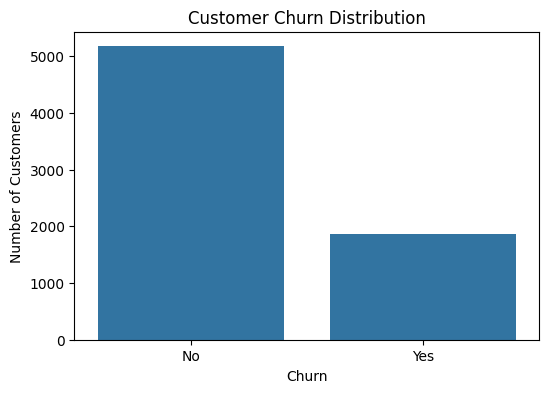

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [9]:
# Churn distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()
# Churn percentage
print(
    df['Churn'].value_counts(normalize=True) * 100
)

In [10]:
# Separate features and target
X = df.drop('Churn', axis=1)

y = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [11]:
# Identify numerical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [13]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


In [14]:
# Check original class distribution
print("Before SMOTE:")
print(y_train.value_counts())

# Apply SMOTE only on training data
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [15]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(
    X_train_balanced,
    y_train_balanced
)

# Predictions
rf_predictions = rf_model.predict(X_test_processed)

# Prediction probabilities
rf_probabilities = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest training completed!")

Random Forest training completed!


In [16]:
# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# Train model
xgb_model.fit(
    X_train_balanced,
    y_train_balanced
)

# Predictions
xgb_predictions = xgb_model.predict(X_test_processed)

# Prediction probabilities
xgb_probabilities = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost training completed!")

XGBoost training completed!


In [17]:
print("RANDOM FOREST EVALUATION")

print("\nAccuracy:",
      accuracy_score(y_test, rf_predictions))

print("\nROC-AUC:",
      roc_auc_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

RANDOM FOREST EVALUATION

Accuracy: 0.7714691270404542

ROC-AUC: 0.8270983492211114

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.77      1409


Confusion Matrix:
[[855 180]
 [142 232]]


In [18]:
print("XGBOOST EVALUATION")

print("\nAccuracy:",
      accuracy_score(y_test, xgb_predictions))

print("\nROC-AUC:",
      roc_auc_score(y_test, xgb_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

XGBOOST EVALUATION

Accuracy: 0.7785663591199432

ROC-AUC: 0.8387920121935467

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1035
           1       0.58      0.62      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409


Confusion Matrix:
[[865 170]
 [142 232]]


In [19]:
results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

print(results)

           Model  Accuracy   ROC-AUC
0  Random Forest  0.771469  0.827098
1        XGBoost  0.778566  0.838792


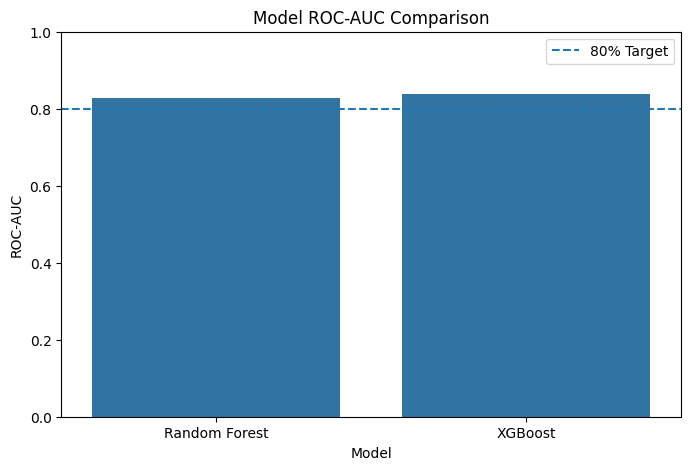

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='ROC-AUC'
)

plt.axhline(
    y=0.80,
    linestyle='--',
    label='80% Target'
)

plt.title('Model ROC-AUC Comparison')
plt.ylim(0, 1)
plt.legend()

plt.show()

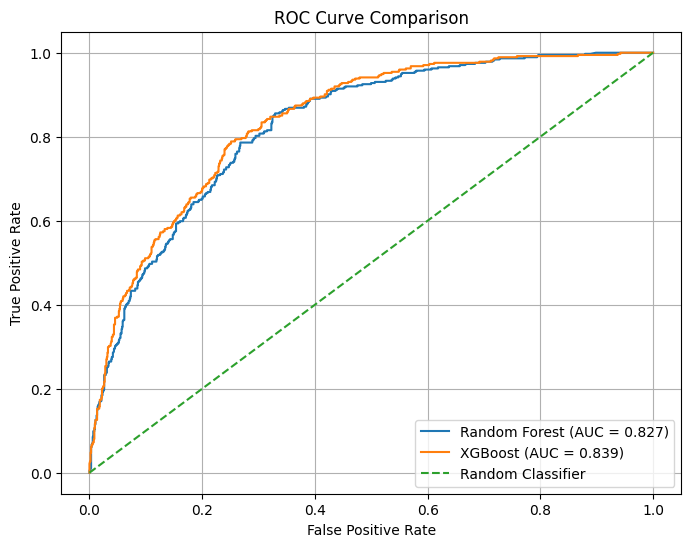

In [21]:
# Calculate ROC curves
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)

# Calculate AUC
rf_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_probabilities
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()

plt.show()

In [22]:
# Get feature names after OneHotEncoding
feature_names = preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importances = xgb_model.feature_importances_

# Create dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
top_10 = feature_importance.head(10)

print(top_10)

                                Feature  Importance
36         cat__Contract_Month-to-month    0.252022
18               cat__OnlineSecurity_No    0.106172
16     cat__InternetService_Fiber optic    0.078678
43  cat__PaymentMethod_Electronic check    0.039223
27                  cat__TechSupport_No    0.037803
38               cat__Contract_Two year    0.036183
37               cat__Contract_One year    0.029841
35             cat__StreamingMovies_Yes    0.022532
39             cat__PaperlessBilling_No    0.021495
11                cat__PhoneService_Yes    0.020644


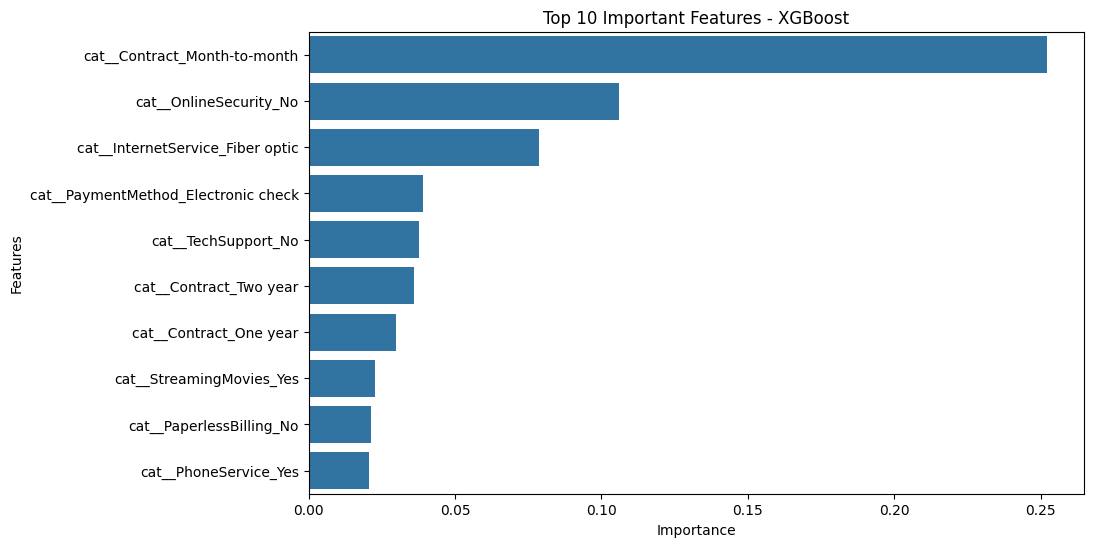

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - XGBoost')

plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

In [24]:
from imblearn.pipeline import Pipeline as ImbPipeline

cv_pipeline = ImbPipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Cross Validation ROC-AUC Scores:")
print(cv_scores)

print("\nMean ROC-AUC:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross Validation ROC-AUC Scores:
[0.81882644 0.81944646 0.83305867 0.82602233 0.84418436]

Mean ROC-AUC: 0.8283076528238625
Standard Deviation: 0.009468672281403606


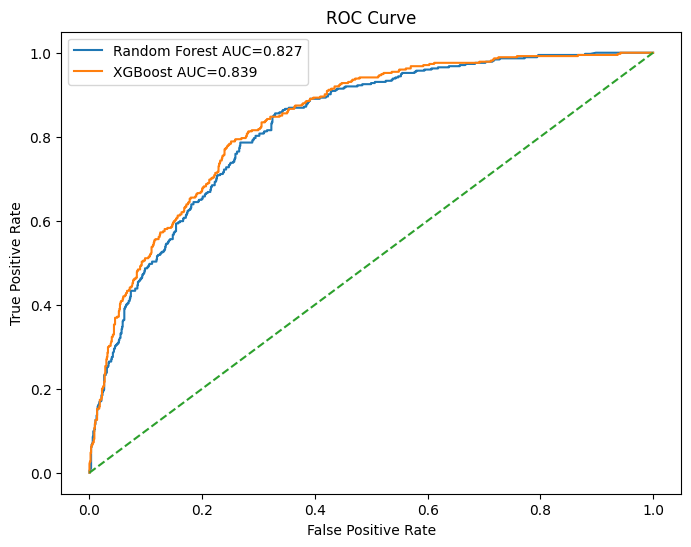

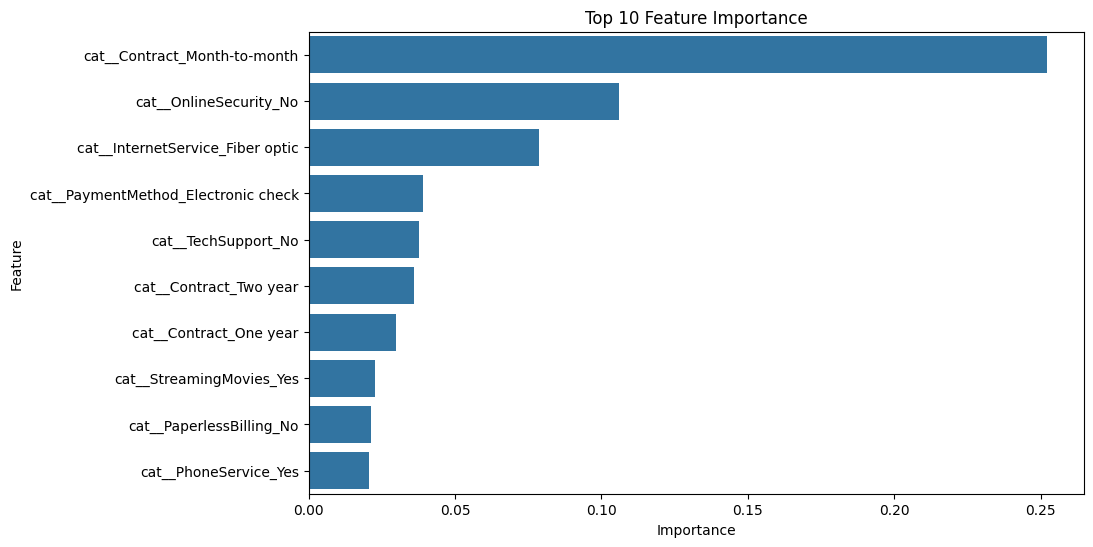

Results saved successfully!


In [25]:
import os

os.makedirs('results', exist_ok=True)

# Save ROC curve
plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest AUC={rf_auc:.3f}')
plt.plot(xgb_fpr, xgb_tpr, label=f'XGBoost AUC={xgb_auc:.3f}')

plt.plot([0, 1], [0, 1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

plt.savefig('results/roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Save feature importance
plt.figure(figsize=(10, 6))

sns.barplot(data=top_10, x='Importance', y='Feature')

plt.title('Top 10 Feature Importance')

plt.savefig(
    'results/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Save model comparison
results.to_csv('results/model_comparison.csv', index=False)

print("Results saved successfully!")

In [26]:
best_model = results.loc[
    results['ROC-AUC'].idxmax()
]

print("PROJECT SUMMARY")
print("-------------------------")

print("Best Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("ROC-AUC:", round(best_model['ROC-AUC'], 4))

if best_model['ROC-AUC'] >= 0.80:
    print("Target achieved: ROC-AUC >= 80%")
else:
    print("Target not achieved: Further tuning required")

PROJECT SUMMARY
-------------------------
Best Model: XGBoost
Accuracy: 0.7786
ROC-AUC: 0.8388
Target achieved: ROC-AUC >= 80%
